# 딥러닝 트랜스포머

### attention

seq2seq: 입력 시퀀스르 받아 다른 시퀀스로 변환하는 모델 구조
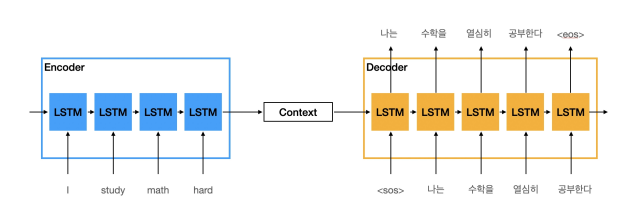

#### 장점
- 입력과 출력의 길이가 달라도 ㄱㄴ
  - 그래서 언어, 어순 달라도 ㄱㄴ

- 인코더: 읽는놈
- 디코더: 만드는놈
- context vector: 인코더가 만든 문장요약본
  - 인코더가 만든 결과물이자, 디코더에 입력으로 들어가는 고정된 크기의 벡터

- 어텐션왜만듦? 병목현상 해결하려고
  - 출력단어마다 필요한 정보를 다르게 반영할 수 x : 왜냐. context vector가 유일한 통로라서
  - 마지막 단어의 정보는 진하고, 앞쪽 단어 정보는 여러 단계 거쳐서 희미해짐 배고프다
  - 그래서 어텐션 만듦. 디코더가 단어 생성할 때마다 입력 문장 전체를 다시 보고, 현재 단어와 관련 o 부분 집중해서 새로운 context vector다시 만듦

  - 어텐션: 현재 시점에서 가장 중요한 정보에 더 높은 가중치를 부여하는 기술

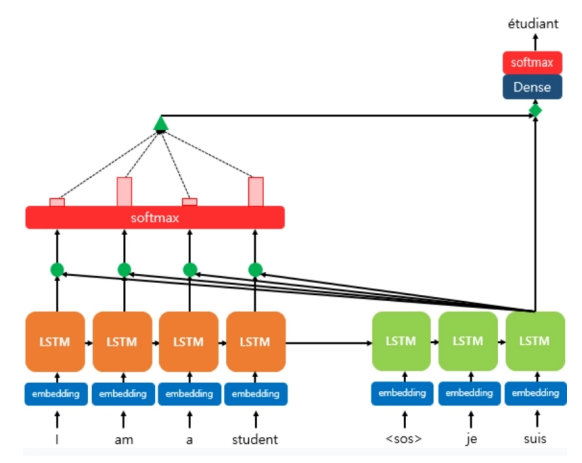

- 기존 swq2seq는 원문 정보를 순차적으로 전달받은 결과만 사용
- 어텐션은 디코더와 인코더의 모든 위치를 직접 비교

### 어텐션의 과정

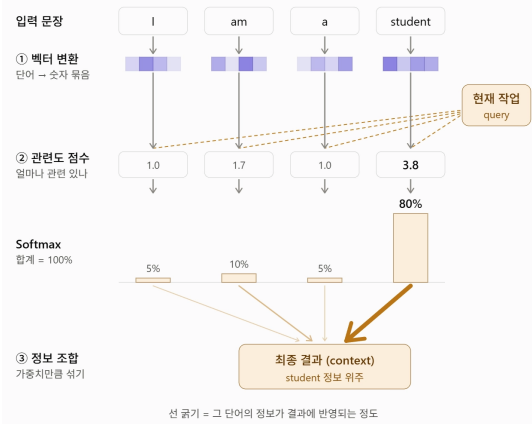

1. 입력을 벡터 형태로 변환
2. 단어별 중요도 계산
  - 관련도 점수: 현재 작업과 각 단어 사이 관련도 점수매김
  - softmax: 관련도 점수를 0~1 사이의 확률값으로 변환, 모든 단어의 중요도 합이 1이 되도록 비율로 바꿔주는함수. 이 비율을 어텐션 가중치라고 함
    - ex) softmax 거쳐서 80퍼센트 가중치가 되면 모델이 student에 80퍼센트 집중하겠다는 뜻이됨
3. 중요도에 따른 입력 정보 조합

- 어텐션 장점:
1. 시간 경과에 대한 유연성
2. 공간에 대한 유연성
3. 병렬화: RNN은 순차 구조라 학습이 느림.
  - attention의 관련도 계산은 각 단어 쌍마다 서로 독립적이므로 동시에 계산 가능

### Attention is All You Need
- Transformer 구조를 처음 발표한 논문
- 어텐션만 있으면 된다
- RNN 기반 모델들의 한계
- Recurrence(순환)과 conv(합성곱)은 필수가 아니다~
  - 병렬화 통한 빠른 학습속도 ㄱㄴ
- 파급력
  - ransformer의 디코더를 쌀은 GPT, 인코더를 쌓은 BERT가 등장,
  - 오늘날 언어 모델의 기반이 됨
  - NLP 평정: 변역 요약 질의응답 등 NLP 표준구조로 자리잡음
  - 음성,이미지 등으로 확장

  # 트랜스포머란?
- RNN처럼 순차처리 안하고 attention만으로 문장 전체의 의미와 구조 파악해서 한번에 처리하는 인코더-디코더 모델.

- 구조
  - self-attention: 문장 안의 단어들이 서로를 참고해 얼마나 중요한 관계르 맺고 잇는지 한번에 문맥파악
  - multi-head attention: 어텐션을 여러 갈래로 나눠서 다양한 관점에서 관계를 파악
  - positional encoding: 각 단어의 위치를 벡터로 만들어 단어 벡터에 더함으로써 사라진 순서 정보를 보완

  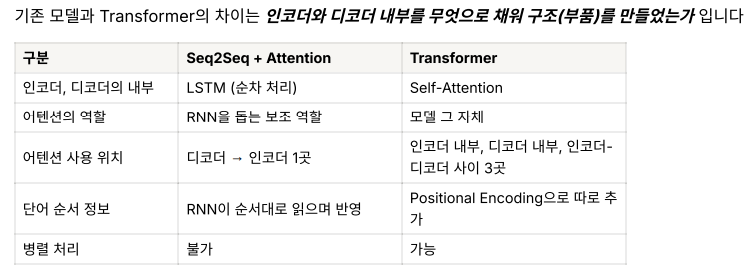

# Self Attention

### 쿼리, 키, 밸류
- 어텐션의 핵심 재료

RNN: 앞뒤 내용이 서로 연관된 d에 대해 기억을 통해 이전 단계에서 처리한 정보ㅡㄹ 현재 단계의 입력에 함께 활용하는 신경망

장기 의존성 문제: 데이터의 후반부에서 초반에 위치한 정보가 잘 반영이 되지 않는 문제


vanishing gradient: RNN은 BPTT(Backpropagation Through Time) 방식 (역전파의 RNN버전)을 사용하다보니 / 이전값드을 현재 값에 적용할 때 가중치가 곱해지는데, 가중치가 계속 곱해지다보면 발산하거나 0으로 수렴하게 된다..... 0이 되면 가중치 사라짐 현상.

LSTM: 배니싱 그라디엔트 극복하려고 만든거
  - "중요한거 오래 기억하고 아닌 건 잊어버리자"
  - 한계: 순서대로 처리하는 구조 자체는 바꾸지 못함.
    - 게이트가 3개려서 계산이 복잡하고 시간이 오래 걸린다
    - 게다가 여전히 긴 문장에 있어서 V.G 현상일어

트랜스포머: 순서대로 처리는 그대로, 대신 모든 단어를 직접 비교!
  - 단어들끼리 비교할 때 쓰이는 애들이 **쿼리, 키, 밸류**

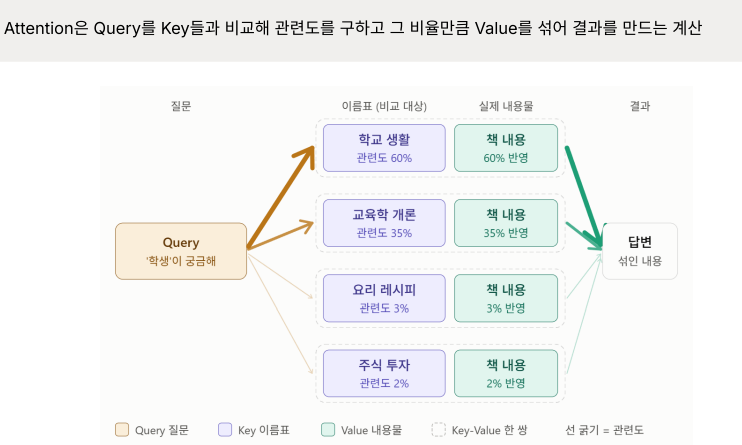

### 쿼리
- 현재 처리 중인 단어가 다른 단어들에게 “지금 나한테 필요한 정보가 뭐지?”라고 묻는 벡터

### 키
- 각 단어가 “나는 이런 정보를 가지고 있어” 라고 보이는 벡터. 즉, 키는 검색 대상이 되는 모든 정보의 ‘이름표’
- Query와 비교하여 관련도 점수를 결정

### 밸류
- 각 단어가 실제로 전달하는 정보 벡터. 관련도 비율만큼 모든 Value를 섞어 최종 결과를 만듦

### cross-attention vs.self-attention

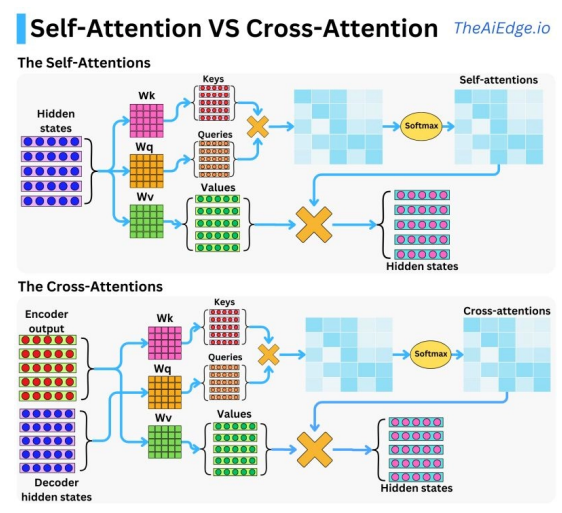

- cross-attention은 하나의 시퀀스가 다른 시퀀스를 참고하여 정보를 만들어내는 매커니즘

  - 디코더가 인코더에게 "어디봐야함?"하는구조

  원문 “The cat is sleeping” → 번역 중 “고양이가 ____.”, 다음 단어를 만드는 순간

  오픈북 시험과 비슷함.  
  답안지를 쓰면서 교과서 계속 흝어보는 과정  
  원문 내부의 관계는 RNN이 순서대로 읽으며 간접적으로 파악하고
병렬 처리 불가하다는 한계 존재

### Self-Attention
- 문장이 스스로에게 “우리끼리 누가 누구와 관련이 있지?”라고 묻는 구조
- RNN 업이도 문장 내부의 관계와 문맥 직접 파악 ㄱㄴ

가을 은행 냄새 지독해... 예시가 강렬하다  
모든 단어가 이 과정을 동시에 거쳐서 각자 문맥이 반영된 new 벡터 얻음 - 병렬 처리 ㄱㄴ



### 스케일드 닷 프로덕트 어텐션
- 어텐션은 쿼리와 키를 비교해서 관련도를 구함.
- 비교는: 스케일드 닷 ~ 의 계산 방법으로 이뤄짐

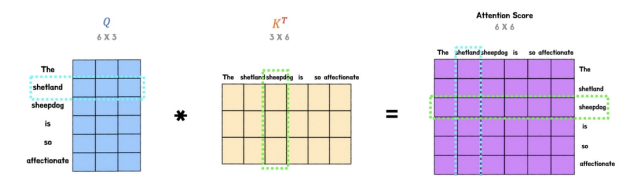

#### 닷프로덕트

내적: 두 벡터의 같은 위치 성분끼리 곱해 모두 더한 값. 방향이 비슷할수록 큰 값 → “얼마나 닮았나”를 숫자로 표현

1. 어텐션 점수 계산
2. 계산된 값에 softmax 적용 -> 어텐션 가중치 산출
  - '이 단어들은 다른 단어들을 몇프로씩 참고하는가?"

#### 스케일드닷프로덕트

- 내적과 소프트맥스 사이에 스케일링 단계 하나 추가!

- Scaled Dot-Product Attention 계산의 결과로 얻어지는 벡터
  - Cross-Attention : Context Vector
  - 현재 생성 중인 단어에 필요한 원문 정보를 비율만큼 모은 벡터
- Self-Attention
  - 문장 내 다른 단어들과의 관계가 반영되어 의미가 업데이트된 단어 벡터

### 멀티헤드 VS 싱글헤드

# 헤드
**헤드는 Attention 계산을 한 번 하는 독립된 단위**

#### 싱글헤드
- 가중치 행렬 세트 하나로, 512차원 벡터를 그대로 한번 Attention함
- 단어마다 가중치 분포 딱 하나 나옴
- 한계: 집중력 100%를 혼자 나눠 써야 함

#### 멀티헤드
- Attention을 작게 쪼개서 여러 번 동시에 하는 방식
- 헤드마다 질문 하나에 집중하고, 결과를 나란히 이어 붙이기 때문에 네 정보가 섞이지 않고 또렷하게 남음

- 작동 방식
1. 분할
2. 병렬 어텐션 계산
3. 결합
4. 최종 투영



# 트랜스포머 전처리 단계

텍스트 입력(Inputs) → 텍스트 토큰화 (Tokenization) → 토큰 임베딩 (Embedding) → Positional Encoding

1. 토큰화
- 걍 조각내기
- 문장 부호도 조각임

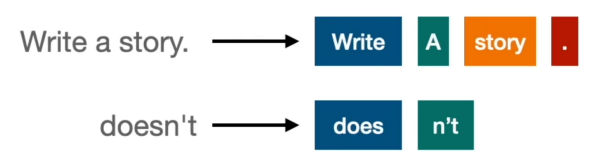

2. 임베딩
- 단어에 좌표 주기
- 단어를 공간적 의미로 표현
  - 반의어는 반대쪽에 있고.. 비슷한 애들끼리 몰려있고
  - word2vec 사용

3. positional encoding: 순서 번호표 붙이기
- Transformer는 모든 단어를 한꺼번에 보기 때문에, 그대로 두면 단어 순서를 모름
- RNN은 순서대로 읽어서 자연스럽게 알았지만, Transformer는 순서를 따로 알려줘야 함




## 인코더와 디코더

### 인코

인코더는 멀티해드와 피듶워드로 이뤄짐

Feed-Forward Network(FFN)?

- 512차원을 2048차원으로 넓혔다가 다시 512차원으로 좁히는 2층 신경망이고, 사이에 ReLU가 들어감
- 단어마다 따로, 같은 가중치로 적용됨  이 단계에서는 단어끼리 정보를 주고 받지 x

1:1 첨삭같은거


Add & Norm: 모든 부품에 붙는 안전장치
- Add = Residual Connection (잔차 연결)
- Norm = Layer Normalization (층 정규화)

### 디코더

1. Masked Multi-Head Self-Attention:
지금까지 쓴 번역 단어끼리 관계 파악 (미래 단어는 가림)
2. Encoder-Decoder Attention (Cross-Attention):
원문 분석 자료(Encoder 출력)에서 필요한 부분 찾기
3. Feed-Forward Network:
Encoder와 동일

Encoder-Decoder Attention이란?
출력 문장 (Decoder)과 입력 문장 (Encoder)을 연결하는 과정

